# Survival Lab

We've looked at normal-linear regression and probit regression from a likelihood perspective, which yields two log-likelihoods:
$$
LL(\beta,\sigma) = - n \log( \sqrt{2\pi} ) - n \log(\sigma) - \frac{1}{2\sigma^2} \sum_{i=1}^n (y_i - x_i \beta)^2
$$
and
$$
LL(\beta) = \sum_{i=1}^N y_i \log(\Phi(x_i \cdot \beta/\sigma)) + (1-y_i) \log(1-\Phi(x_i \cdot \beta/\sigma)).
$$
This lab combines them by looking at **right-censored** survival data.

We are going to use the Metabric breast cancer dataset to predict how long someone survives after being treated for breast cancer. For the regressions that follow, include the following as numeric variables:

- 'Age at Diagnosis'
- 'Lymph nodes examined positive'
- 'Mutation Count'
- 'Tumor Size'

and the following as categorical variables (one-hot encode them):

- 'Chemotherapy'
- 'Hormone Therapy'
- 'Radio Therapy'
- 'Tumor Stage'

The outcome variable of interest is the log of `Overall Survival (Months)`, which we'll refer to as log-months.

1. Load the `./data/metabric.csv` data. Tabulate `Overall Survival Status` to see who is alive or dead at the time the study ends. Make a kernel density plot of `Overall Survival (Months)`, hued by `Overall Survival Status`, to see the difference between survival duration for those alive and those dead at the time the study ended. **Drop the observations for which `Tumor Stage` is zero.**
2. Use Scikit's `train_test_split` with a `test_size` of .2. There are two tempting -- but ultimately incorrect -- ways to handle the Survival Status issue:
    - Use the reported `Overall Survival (Months)` as the target variable
    - Drop everyone who is alive at the time the study ends
Run these flawed regressions and save the coefficients and test-set predictions. Explain clearly how the first option is an example of imputation and the second treats survival as missing data.
3. Derive the log-likelihood for a model where the normal density is used for log-months when the subject died during the study (and log-months is observed, as in linear-normal regression), and the survival probability based on the Normal distribution is used when the patient is alive when the study ends (and log-months is a latent variable, as in a binary probit).
4. We want to estimate the model in part 3. You can do this with the `lifelines` package's `LogNormalAFTFitter`, or use the code chunk below to extend StatsModels to estimate this kind of model.
5. Compare the coefficients and test-set predictions (be careful to keep an eye on the censoring) for the censored MLE and the two linear models. Can you identify any groups who receive systematically biased predictions from the imputation and missing data approaches? 

In [1]:
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.model_selection import train_test_split

from scipy.stats import norm
from statsmodels.base.model import GenericLikelihoodModel

### Question 1

In [2]:
metabric = pd.read_csv('metabric.csv')

# drop observations where tumor size is zero 
metabric = metabric[metabric["Tumor Stage"] != 0]

In [3]:
# tabulate overall survival status 
print(metabric["Overall Survival Status"].value_counts(dropna=False))

Overall Survival Status
1:DECEASED    768
0:LIVING      573
Name: count, dtype: int64


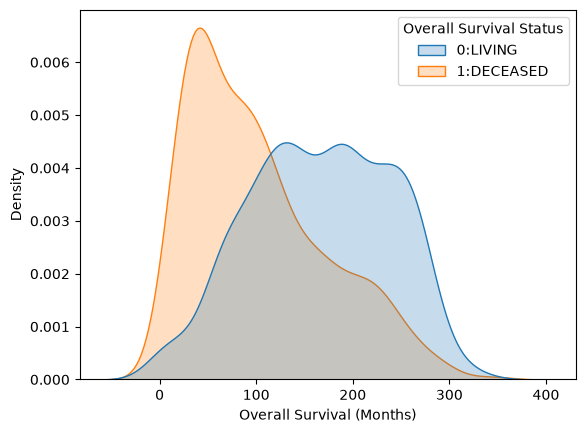

In [4]:
# kde plot 
sns.kdeplot(data=metabric, x="Overall Survival (Months)",
            hue="Overall Survival Status", common_norm=False, fill=True)
plt.show()

### Question 2

In [5]:
#train-test split
train, test = train_test_split(metabric, test_size=0.2, random_state=42)

In [6]:
numeric = ['Age at Diagnosis',
           'Lymph nodes examined positive',
           'Mutation Count',
           'Tumor Size']

categorical = ['Chemotherapy',
               'Hormone Therapy',
               'Radio Therapy',
               'Tumor Stage']

In [7]:
X_train = pd.get_dummies(train[numeric + categorical],
                         columns=categorical, drop_first=True, dtype=int)

X_test = pd.get_dummies(test[numeric + categorical],
                        columns=categorical, drop_first=True, dtype=int)

X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

In [8]:
X_train = sm.add_constant(X_train)
X_test = sm.add_constant(X_test, has_constant='add')

In [9]:
y_train = np.log(train['Overall Survival (Months)'])
y_test = np.log(test['Overall Survival (Months)'])

In [10]:
# Model 1: imputation
ols_all = sm.OLS(y_train, X_train).fit()

print(ols_all.summary())

                                OLS Regression Results                               
Dep. Variable:     Overall Survival (Months)   R-squared:                       0.121
Model:                                   OLS   Adj. R-squared:                  0.113
Method:                        Least Squares   F-statistic:                     14.60
Date:                       Tue, 17 Nov 2026   Prob (F-statistic):           1.48e-24
Time:                               13:33:58   Log-Likelihood:                -1329.2
No. Observations:                       1072   AIC:                             2680.
Df Residuals:                           1061   BIC:                             2735.
Df Model:                                 10                                         
Covariance Type:                   nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------

In [11]:
# coeffients and predictions
coef_all = ols_all.params
pred_all = ols_all.predict(X_test)

In [12]:
# Model 2: missing data
train_dead = train[train['Overall Survival Status'] == '1:DECEASED']

X_train_dead = X_train.loc[train_dead.index]
y_train_dead = y_train.loc[train_dead.index]

ols_dead = sm.OLS(y_train_dead, X_train_dead).fit()

print(ols_dead.summary())

                                OLS Regression Results                               
Dep. Variable:     Overall Survival (Months)   R-squared:                       0.152
Model:                                   OLS   Adj. R-squared:                  0.138
Method:                        Least Squares   F-statistic:                     10.81
Date:                       Tue, 17 Nov 2026   Prob (F-statistic):           5.18e-17
Time:                               13:33:59   Log-Likelihood:                -764.43
No. Observations:                        615   AIC:                             1551.
Df Residuals:                            604   BIC:                             1600.
Df Model:                                 10                                         
Covariance Type:                   nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------

In [13]:
#coeffients and predictions
coef_dead = ols_dead.params
pred_dead = ols_dead.predict(X_test)

Model 1 reports the survival months of all patients, even those who were still alive until the end of the study. Therefore, the survival time includes the whole time until the trial ended even though their survival time post-trial is unknown. Therefore, predictions are biased downward, since some patients may survive longer than recorded survival time.

Model 2 treats surviving as missing data. Since we have removed this data and are no longer running the tests on it, we are removing all of the patients who survived, and therefore skewing the experiment. 

Both of these approached throw away valuable data about the patients who survived the course of the study. 

### Question 3

For patient $i$, let $y_i=\log{\text{reported months}}$. 

If the patient died during the study, $d = 1$, the normal density is used:

$$\text{log-likelihood} = -\log(\sigma) - \frac{1}{2}\log(2 \pi) - \frac{(y_i - x_i \beta)^2}{2\sigma ^2}$$

If the patient is alive, $d = 0$, use the survival probability:

$$\text{log-likelihood} = \log{ \Phi \bigg(\frac{x_i \beta - y_i}{ \sigma}\bigg)}$$

where $\Phi$ is the standard normal CDF.

$$\text{full log-likelihood} = \sum_i {d_i \bigg[\frac{-1}{2} \log{(2 \pi)} - \log {\sigma} - \frac{(y_i - x_i \beta)^2}{2 \sigma^2} \bigg] + (1-d_i) \log \Phi \bigg(\frac{x_i \beta - y_i }{ \sigma}\bigg)}

### Question 4

In [14]:
#variables

train['event'] = (train['Overall Survival Status'] == '1:DECEASED').astype(int)
test['event'] = (test['Overall Survival Status'] == '1:DECEASED').astype(int)

In [15]:
# given code, edited for defined variables

class CensoredNormalMLE(GenericLikelihoodModel):
    def __init__(self, endog, exog, event, **kwds):
        super().__init__(endog, exog, extra_params_names=["log_sigma"], **kwds)
        self.event = np.asarray(event)

    def nloglikeobs(self, params):
        beta, log_sigma = params[:-1], params[-1]
        sigma = np.exp(log_sigma)
        z = (self.endog - self.exog @ beta) / sigma
        ll_dead = norm.logpdf(z) - log_sigma
        ll_alive = norm.logsf(z)
        return -np.where(self.event == 1, ll_dead, ll_alive)

start = np.r_[ols_all.params, np.log(np.sqrt(np.mean(ols_all.resid ** 2)))]

model = CensoredNormalMLE(y_train, X_train, train['event'])
mle = model.fit(start_params=start, method="bfgs", maxiter=1000, disp=False)

print("Converged:", mle.mle_retvals["converged"])
print(mle.summary())

Converged: True
                              CensoredNormalMLE Results                              
Dep. Variable:     Overall Survival (Months)   Log-Likelihood:                -1201.4
Model:                     CensoredNormalMLE   AIC:                             2427.
Method:                   Maximum Likelihood   BIC:                             2487.
Date:                       Tue, 17 Nov 2026                                         
Time:                               13:34:03                                         
No. Observations:                       1072                                         
Df Residuals:                           1060                                         
Df Model:                                 10                                         
                                    coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

### Question 5

In [16]:
# comparing coefficients

coef_mle = pd.Series(mle.params[:-1], index=X_train.columns)

coef_comparison = pd.DataFrame({
    'Imputation': coef_all,
    'Missing Data': coef_dead,
    'Censored MLE': coef_mle
})

coef_comparison

,Imputation,Missing Data,Censored MLE
const,5.293352,4.659419,6.761228
Age at Diagnosis,-0.008551,-0.002901,-0.021836
Lymph nodes examined positive,-0.038357,-0.027944,-0.056686
Mutation Count,0.006382,0.009611,-0.016831
Tumor Size,-0.003829,-0.001833,-0.008705
Chemotherapy_YES,-0.219118,-0.393093,-0.272630
Hormone Therapy_YES,0.086354,0.242348,0.261282
Radio Therapy_YES,0.120239,0.039192,0.213519
Tumor Stage_2.0,-0.187168,-0.223816,-0.322433
Tumor Stage_3.0,-0.405198,-0.552826,-0.553192


In [17]:
# comparing predictions by survival status

pred_mle = pd.Series(X_test @ mle.params[:-1], index=X_test.index)

pred_comparison = pd.DataFrame({
    'Imputation': pred_all,
    'Missing Data': pred_dead,
    'Censored MLE': pred_mle,
    'Event': test['event']
})

pred_comparison.head()

,Imputation,Missing Data,Censored MLE,Event
804,4.779502,4.497828,5.369038,0
550,4.985947,4.612540,5.600707,0
572,4.630981,4.480401,5.211996,0
432,4.775639,4.504458,5.582498,0
260,4.388073,3.995049,5.046307,0


In [18]:
# comparing predictions by survival status

pred_comparison.groupby('Event')[
    ['Imputation', 'Missing Data', 'Censored MLE']
].mean()

,Imputation,Missing Data,Censored MLE
Event,,,
0,4.674281,4.418899,5.211648
1,4.463285,4.276382,4.790679


Mutation Count stands out for imputation and missing data compared to MLE. The coefficients for these are positive, whereas for MLE it is negative. We could assume age is also biased since we either add a value or drop the row when the data is missing, but this could likely mean we are missing out on longer life results for these respondents. It could also mean that patients with a greater amount of positive lymph nodes and larger tumors were overpredicted since the two models has negative coefficients then censored MLE. The interepts for each model also differ by ~1. This tells us that when all predictors equal 0, the expected y would be different for each model. In the predictions above, we can see that the models estimate different survival times for the same person. Censored MLE seems to always have the highest predicted survival. 